# PhishGuard — ViT Fine-Tuning (Phishing vs Legitimate)

This notebook contains a complete walkthrough with code explanations, expected outputs after each phase, and structured phases.

| Phase | Objective | Description & Expected Output |
| :--- | :--- | :--- |
| **0** | **Setup & Config** | Environment initialization, setting random seed, selecting the appropriate device (GPU/CPU), and installing required libraries. |
| **1** | **Dataset Loading** | Loading the pre-cleaned and pre-split dataset directly. **Important:** Never perform a re-split to prevent data leakage. Ensure paths follow: `split/phishing/*.png` and `split/legitimate/*.png`. |
| **2** | **Model Initialization** | Loading the pretrained Vision Transformer model (`google/vit-base-patch16-224`) along with its image processor and classification head. |
| **3** | **Head Training** | Training the classification head exclusively while freezing the backbone layers. |
| **4** | **Fine-Tuning** | Unfreezing the final blocks of the model and fine-tuning with a smaller learning rate (e.g., $2\times 10^{-5}$). |
| **5** | **Evaluation & MLflow** | Testing the model on the Test split, computing metrics (Precision, Recall, F1, ROC-AUC), and logging experiments to MLflow. |
| **6** | **External Validation** | Running external validation on the **Phish-Iris** dataset to benchmark generalization. |
| **7** | **Inference & Deliverables** | Saving the best model weights, configuration files, processor assets, and generating final inference outputs. |

###  Setup & Configuration
* **Objective:** Initialize the configuration dictionary (`CFG`) containing all paths to the clean, pre-split dataset (`train`, `val`, `test`), hyperparameters, and model specifications.
* **Output:** Creates output directories and sets up the foundational configuration for the Vision Transformer pipeline.


In [68]:
import torch

print("----------------------------------------")
print("1. Is GPU Available? ->", torch.cuda.is_available())
if torch.cuda.is_available():
    print("2. GPU Device Name  ->", torch.cuda.get_device_name(0))
    print("3. Current Device ID ->", torch.cuda.current_device())
    x = torch.tensor([1.0, 2.0]).to("cuda")
    print("4. Test Tensor on GPU ->", x.device)
else:
    print("⚠️ WARNING: PyTorch is running on CPU!")
print("----------------------------------------")

----------------------------------------
1. Is GPU Available? -> True
2. GPU Device Name  -> NVIDIA GeForce RTX 4050 Laptop GPU
3. Current Device ID -> 0
4. Test Tensor on GPU -> cuda:0
----------------------------------------


In [69]:
# =====================================================================
# Safe Setup & Device Initialization (Preventing Kernel Crash)
# =====================================================================
import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets
from transformers import ViTImageProcessor, ViTForImageClassification, get_cosine_schedule_with_warmup

from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay, roc_curve, classification_report
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()


Using Device: cuda
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [70]:
# Configuration Dictionary
CFG = dict(
    train_dir="cv_work/clean_dataset/train",  
    val_dir="cv_work/clean_dataset/val",      
    test_dir="cv_work/clean_dataset/test",    
    external_dir="data/phish_iris",
    
    model_name="google/vit-base-patch16-224",
    out_dir="outputs/vit_phishguard",
    num_workers=0,  # 0 is recommended on Windows to avoid multiprocessing spawn issues
    seed=42,
    fp16=True,      # Mixed precision for faster GPU training and lower VRAM
    
    p1=dict(epochs=3, lr=1e-3, bs=32),
    p2=dict(epochs=10, lr=2e-5, bs=32, last_n_blocks=4, wd=0.01, warmup=0.1),
    es=dict(patience=3, min_delta=5e-4)
)

os.makedirs(CFG["out_dir"], exist_ok=True)
print("Configuration loaded successfully!")


Configuration loaded successfully!


# Data

* **Official ViTImageProcessor:** Use the model's official processor for $224 \times 224$ resizing and normalization using the exact mean/std required by the model.
* **Light Augmentation:** Avoid heavy augmentations (like crop/jitter) because website layouts are extremely sensitive to spatial changes; use minimal augmentation only if overfitting occurs.
* **Class Weights:** Class weights are computed directly from the training split (`train`) to handle class imbalance (e.g., phishing vs. legitimate ratio).
* **Label Mapping & Order:** Ensure the class order is explicitly mapped as `['legitimate', 'phishing']` (where label = 1 means phishing) and verify the number of samples in each split.


###  Processor & Custom Dataset Class
* **Objective:** Load the official `ViTImageProcessor` from Hugging Face for required $224 \times 224$ resizing and normalization. Define a custom `ViTFolder` class extending PyTorch's `ImageFolder` to handle RGB conversion and tensor formatting seamlessly.
* **Output:** Prepares the custom pipeline required to feed images into the Vision Transformer backbone.


In [71]:
# Load Official ViT Image Processor for 224x224 resizing & normalization
processor = ViTImageProcessor.from_pretrained(CFG["model_name"])

# Custom Dataset Wrapper to work seamlessly with ViT Image Processor
class ViTFolder(datasets.ImageFolder):
    def __init__(self, root, processor):
        super().__init__(root)
        self.processor = processor
        
    def __getitem__(self, index):
        img, y = super().__getitem__(index)
        pixel_values = self.processor(images=img.convert("RGB"), return_tensors="pt")["pixel_values"][0]
        return pixel_values, y

print("ViT Image Processor and Custom Dataset class ready!")

ViT Image Processor and Custom Dataset class ready!


In [72]:
def loader(root, bs, shuffle):
    ds = ViTFolder(root, processor)
    return ds, DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=CFG["num_workers"], pin_memory=DEVICE=="cuda")

train_ds, train_dl1 = loader(CFG["train_dir"], CFG["p1"]["bs"], True)
_,        train_dl2 = loader(CFG["train_dir"], CFG["p2"]["bs"], True)
val_ds,   val_dl    = loader(CFG["val_dir"], 64, False)
test_ds,  test_dl   = loader(CFG["test_dir"], 64, False)
assert train_ds.classes == ["legitimate", "phishing"], train_ds.classes

for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    c = np.bincount(ds.targets, minlength=2)
    print(f"{name:5s} n={len(ds):6d}  legitimate={c[0]}  phishing={c[1]}")

train n= 17042  legitimate=12378  phishing=4664
val   n=  3651  legitimate=2652  phishing=999
test  n=  3651  legitimate=2652  phishing=999


###  Visualizing Training Samples
* **Objective:** Sample and plot a grid of random training images along with their respective ground-truth labels (`legitimate` vs `phishing`).
* **Expected Result:** Renders an 8-image subplot grid to visually inspect website screenshots before model ingestion.


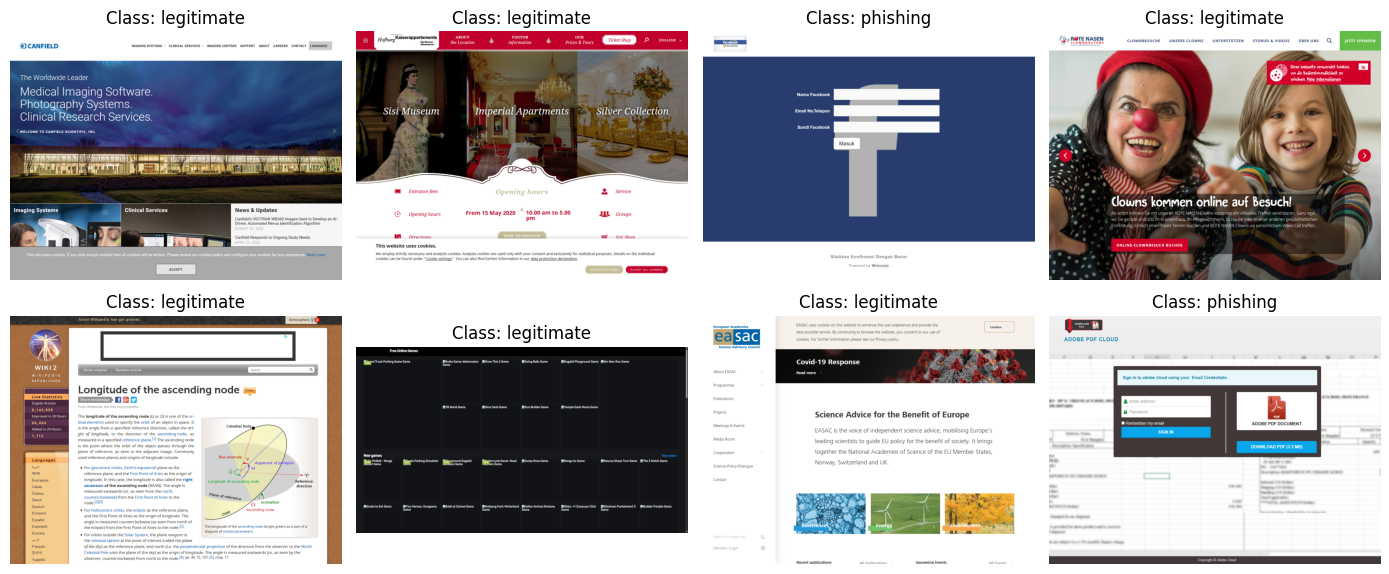


Phase 1 completed successfully across cells!


In [73]:

fig, ax = plt.subplots(2, 4, figsize=(14, 6))
idxs = random.sample(range(len(train_ds)), 8)
for a, idx in zip(ax.ravel(), idxs):
    img_path, label = train_ds.samples[idx]
    raw_img = plt.imread(img_path) if img_path.lower().endswith("png") else None
    if raw_img is not None:
        a.imshow(raw_img)
    a.set_title(f"Class: {train_ds.classes[label]}")
    a.axis("off")
plt.tight_layout()
plt.show()
print("\nPhase 1 completed successfully across cells!")

### Model Initialization & Class Weights
* **Model Loading:** Load `google/vit-base-patch16-224` with a custom classification head (`num_labels=2`). The warning *"some weights were not initialized"* is completely normal because the classification head is brand new.
* **Class Weights (Imbalance Handling):** Compute class weights dynamically from the training dataset targets to handle any class imbalance between `legitimate` and `phishing` samples using `CrossEntropyLoss`.


In [74]:
model = ViTForImageClassification.from_pretrained(
    CFG["model_name"], num_labels=2, id2label={0: "legitimate", 1: "phishing"},
    label2id={"legitimate": 0, "phishing": 1}, ignore_mismatched_sizes=True)

# Initialize fresh classification head properly to ensure stable fp16 training
nn.init.trunc_normal_(model.classifier.weight, std=0.02)
nn.init.zeros_(model.classifier.bias)
model = model.to(DEVICE)
print(f"total params: {sum(p.numel() for p in model.parameters()):,}")

cnt = np.bincount(train_ds.targets, minlength=2)
class_w = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_w)
print("class weights:", class_w.tolist())


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


total params: 85,800,194
class weights: [0.6883987784385681, 1.8269726037979126]


In [75]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y, L, n = [], [], 0.0, 0
    ce = nn.CrossEntropyLoss(reduction="sum")
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE); lg = model(pixel_values=x).logits
        L += ce(lg, y).item(); n += len(y)
        P.append(torch.softmax(lg, -1)[:, 1].cpu()); Y.append(y.cpu())
    return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / n

In [76]:
def compute_metrics(y, p, thr=0.5):
    pr = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, pr), precision=precision_score(y, pr, zero_division=0),
                recall=recall_score(y, pr, zero_division=0), f1=f1_score(y, pr, zero_division=0),
                roc_auc=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

In [77]:
def set_trainable(model, head_only, last_n=0):
    for p in model.parameters(): p.requires_grad = False
    for p in model.classifier.parameters(): p.requires_grad = True
    if not head_only:
        for blk in model.vit.encoder.layer[-last_n:]:
            for p in blk.parameters(): p.requires_grad = True
        for p in model.vit.layernorm.parameters(): p.requires_grad = True
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [78]:
HIST = []
STEP = 0
BEST = dict(f1=0.0, phase="", epoch=0)

def run_phase(name, model, dl, pc, head_only):
    global STEP
    ntr = set_trainable(model, head_only, pc.get("last_n_blocks", 0))
    print(f"[{name}] trainable params: {ntr:,}"); mlflow.log_param(f"{name}_trainable_params", ntr)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=pc["lr"], weight_decay=pc.get("wd", 0.0))
    total = pc["epochs"] * len(dl)
    sched = get_cosine_schedule_with_warmup(opt, int(pc.get("warmup", 0.0) * total), total)
    use_amp = (DEVICE == "cuda" and CFG.get("fp16", False))
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    bad = 0
    for ep in range(pc["epochs"]):
        model.train(); run, n = 0.0, 0
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad()
            with torch.autocast(DEVICE, enabled=use_amp):
                loss = criterion(model(pixel_values=x).logits, y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(y); n += len(y)
        p, yv, vl = predict(model, val_dl); m = compute_metrics(yv, p)
        row = dict(phase=name, epoch=ep + 1, train_loss=run / n, val_loss=vl, val_f1=m["f1"],
                   val_precision=m["precision"], val_recall=m["recall"], val_auc=m["roc_auc"], val_acc=m["accuracy"])
        HIST.append(row); STEP += 1
        mlflow.log_metrics({f"{name}/{k}": v for k, v in row.items() if isinstance(v, float)}, step=STEP)
        print(f"[{name}] ep{ep+1:02d} train_loss={row['train_loss']:.4f} val_loss={vl:.4f} "
              f"val_f1={m['f1']:.4f} val_auc={m['roc_auc']:.4f}")
        if m["f1"] > BEST["f1"] + CFG["es"]["min_delta"]:
            BEST.update(f1=m["f1"], phase=name, epoch=ep + 1); bad = 0
            model.save_pretrained(CFG["out_dir"], safe_serialization=True)
            torch.save(model.state_dict(), os.path.join(CFG["out_dir"], "best_model.pt"))
            print("   ✔ new best saved")
        else:
            bad += 1
            if bad >= CFG["es"]["patience"]: print(f"   early stopping @ epoch {ep+1}"); break


In [79]:
def plot_hist(phase):
    h = [r for r in HIST if r["phase"] == phase]; e = [r["epoch"] for r in h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(e, [r["train_loss"] for r in h], label="train"); ax[0].plot(e, [r["val_loss"] for r in h], label="val")
    ax[0].set_title(f"{phase} loss"); ax[0].legend()
    ax[1].plot(e, [r["val_f1"] for r in h], label="F1"); ax[1].plot(e, [r["val_auc"] for r in h], label="AUC")
    ax[1].set_title(f"{phase} val metrics"); ax[1].legend(); plt.tight_layout(); plt.show()

###  Head-only training (backbone frozen)
* **Objective**: Train the newly initialized classification head (`classifier`) using a higher learning rate ($1e-3$) while keeping the pretrained backbone frozen[span_0](start_span)[span_0](end_span)[span_1](start_span)[span_1](end_span).
* **Monitoring**: Keep an eye on validation F1/AUC. If F1 is close to $0.5$, check for potential issues in data labels or paths. Ensure metrics improve rapidly and stabilize[span_2](start_span)[span_2](end_span).


In [80]:
import mlflow
mlflow.end_run()

In [ ]:
import mlflow

from transformers import get_cosine_schedule_with_warmup
processor.save_pretrained(CFG["out_dir"])
run = mlflow.start_run(run_name="vit_two_phase")
mlflow.log_params({"model": CFG["model_name"], "seed": CFG["seed"], "train_n": len(train_ds), "val_n": len(val_ds),
                   "test_n": len(test_ds), **{f"p1_{k}": v for k, v in CFG["p1"].items()},
                   **{f"p2_{k}": v for k, v in CFG["p2"].items()}, **{f"es_{k}": v for k, v in CFG["es"].items()}})
run_phase("phase1", model, train_dl1, CFG["p1"], head_only=True)
plot_hist("phase1"); print("best so far:", BEST)

[phase1] trainable params: 1,538


In [ ]:
model = ViTForImageClassification.from_pretrained(CFG["out_dir"]).to(DEVICE)   # best من Phase 3
run_phase("phase2", model, train_dl2, CFG["p2"], head_only=False)
plot_hist("phase2"); print("BEST:", BEST)
import pandas as pd; display(pd.DataFrame(HIST).round(4))

In [ ]:
best_model = ViTForImageClassification.from_pretrained(CFG["out_dir"]).to(DEVICE)
p, y, _ = predict(best_model, test_dl); M = compute_metrics(y, p)
print(pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in M.items()}))
print(classification_report(y, (p >= .5).astype(int), target_names=["legitimate", "phishing"], digits=4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y, (p >= .5).astype(int)), display_labels=["legit", "phish"]).plot(ax=ax[0], colorbar=False)
fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr, label=f"AUC={M['roc_auc']:.4f}"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC (test)")
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "test_plots.png"), dpi=150); plt.show()

mlflow.log_metrics({f"test_{k}": v for k, v in M.items()})
mlflow.log_params({"best_phase": BEST["phase"], "best_epoch": BEST["epoch"]})
json.dump({"test": M, "best": BEST}, open(os.path.join(CFG["out_dir"], "test_metrics.json"), "w"), indent=2)
pd.DataFrame(HIST).to_csv(os.path.join(CFG["out_dir"], "training_history.csv"), index=False)
for f in ["config.json", "preprocessor_config.json", "model.safetensors", "test_metrics.json", "test_plots.png", "training_history.csv"]:
    mlflow.log_artifact(os.path.join(CFG["out_dir"], f))

In [ ]:
if os.path.exists(CFG["external_dir"]):
    ext_ds, ext_dl = loader(CFG["external_dir"], 64, False)
    assert ext_ds.classes == ["legitimate", "phishing"], ext_ds.classes
    pe, ye, _ = predict(best_model, ext_dl); ME = compute_metrics(ye, pe)
    print(f"Phish-Iris n={len(ext_ds)}"); print(pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in ME.items()}))

    cmp = pd.DataFrame({"internal_test": M, "phish_iris": ME}).loc[["accuracy", "precision", "recall", "f1", "roc_auc"]]
    display(cmp.round(4)); cmp.plot.bar(figsize=(7, 3.5), ylim=(0, 1.05)); plt.title("Internal test vs Phish-Iris"); plt.show()

    mlflow.log_metrics({f"ext_{k}": v for k, v in ME.items()})
    json.dump(ME, open(os.path.join(CFG["out_dir"], "external_phish_iris_metrics.json"), "w"), indent=2)
    mlflow.log_artifact(os.path.join(CFG["out_dir"], "external_phish_iris_metrics.json"))
else:
    print(f"[INFO] External dataset path '{CFG['external_dir']}' not found. Skipping external validation benchmark.")
mlflow.end_run()


In [ ]:
from PIL import Image
def classify(path, model_dir=CFG["out_dir"], thr=0.5):
    proc = ViTImageProcessor.from_pretrained(model_dir)
    m = ViTForImageClassification.from_pretrained(model_dir).to(DEVICE).eval()
    x = proc(images=Image.open(path).convert("RGB"), return_tensors="pt")["pixel_values"].to(DEVICE)
    with torch.no_grad(): pp = torch.softmax(m(pixel_values=x).logits, -1)[0, 1].item()
    return {"label": "phishing" if pp >= thr else "legitimate", "p_phishing": round(pp, 4)}

result = classify("some_screenshot.png")
print(result)
for f in sorted(os.listdir(CFG["out_dir"])): print(f"{os.path.getsize(os.path.join(CFG['out_dir'], f))/1e6:8.2f} MB  {f}")
#   experiments: !mlflow ui --backend-store-uri ./mlruns